<a href="https://colab.research.google.com/github/oumaklaus/Deathon-ML-Internship/blob/main/Iris_classification_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Data Loading


In [1]:
import urllib.request

base_url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
iris = "iris.csv"
urllib.request.urlretrieve(base_url, iris)

('iris.csv', <http.client.HTTPMessage at 0x78602b94ead0>)

In [2]:
!ls

iris.csv  sample_data


In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score, classification_report,confusion_matrix, ConfusionMatrixDisplay)
RANDOM_STATE = 42
sns.set_theme(style = "whitegrid")


In [4]:
df = pd.read_csv("iris.csv")

# 2. EDA

In [5]:
df.shape

(150, 5)

In [6]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [7]:
df.tail()

,sepal_length,sepal_width,petal_length,petal_width,species
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


In [8]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [9]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [10]:
df['species'].value_counts()

,count
species,
setosa,50
versicolor,50
virginica,50


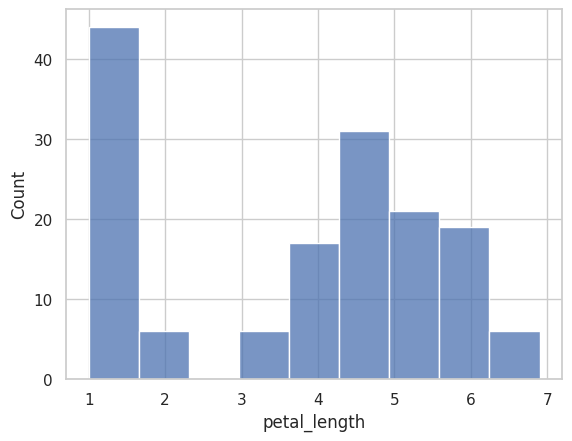

In [29]:
sns.histplot(data=df, x = "petal_length")
plt.show()

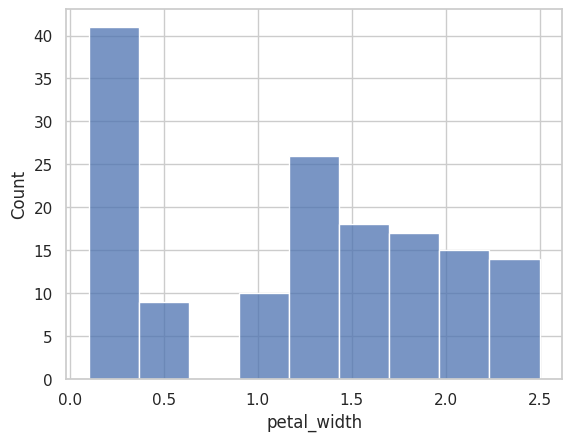

In [30]:
sns.histplot(data=df, x = "petal_width")
plt.show()

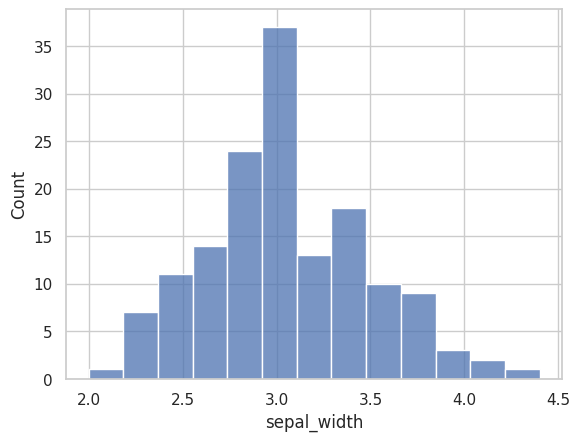

In [32]:
sns.histplot(data=df, x = "sepal_width")
plt.show()

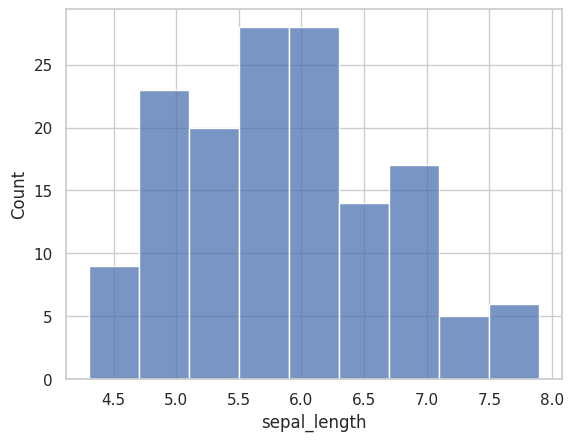

In [33]:
sns.histplot(data=df, x = "sepal_length")
plt.show()

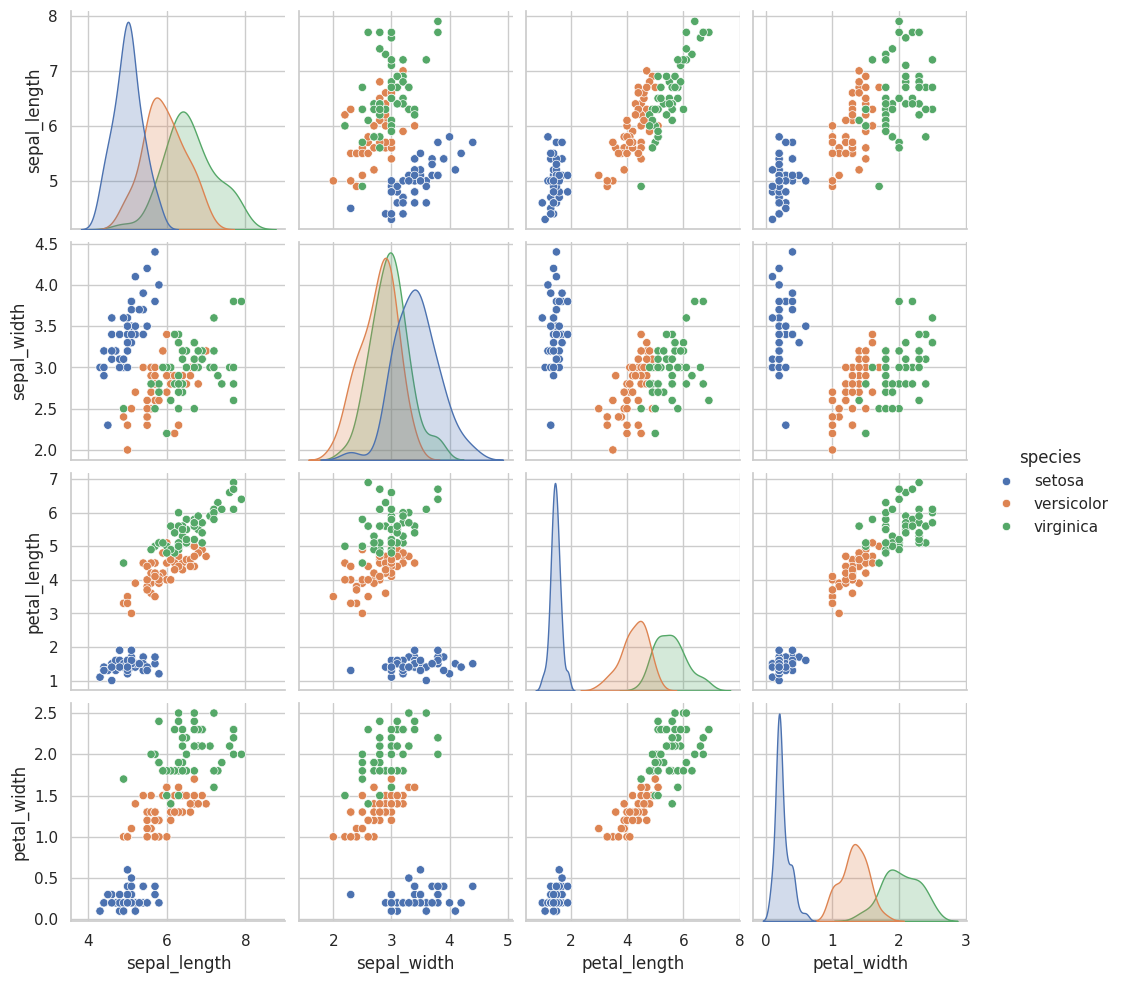

In [13]:
sns.pairplot(df, hue = 'species')

<Axes: >

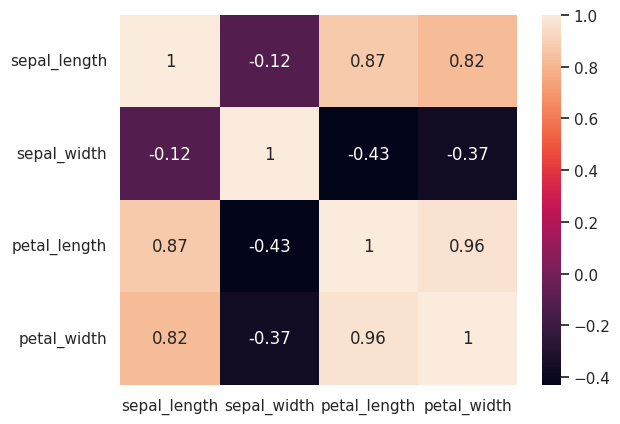

In [14]:
sns.heatmap(df.drop(columns='species').corr(), annot=True)

## 3. Dataset Splitting

In [15]:
X = df.drop(columns = "species")
y = df["species"]

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = RANDOM_STATE, stratify=y)

In [17]:
print("X Train: ", X_train.shape)

X Train:  (120, 4)


In [18]:
print("X Test: ", X_test.shape)

X Test:  (30, 4)


## 4. Feature Scaling

In [19]:
scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

## 5. Model Training

In [20]:
log_reg = LogisticRegression()
tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)

log_reg.fit(X_train_s, y_train)
tree.fit(X_train_s, y_train)

pred_lr = log_reg.predict(X_test_s)
pred_tree = tree.predict(X_test_s)

## 6. Model Evaluation

In [21]:
print("Logistic Regression")
print(classification_report(y_test, pred_lr))

print("Decision Tree")
print(classification_report(y_test, pred_tree))

Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



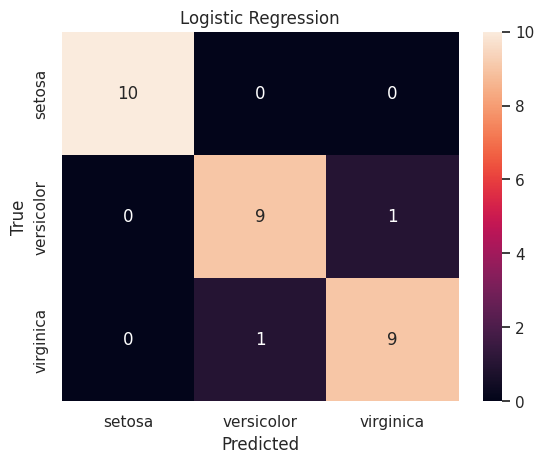

In [22]:
labels = ["setosa", "versicolor", "virginica"]

sns.heatmap(confusion_matrix(y_test, pred_lr), annot=True, fmt="d",
            xticklabels=labels, yticklabels=labels)
plt.title("Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

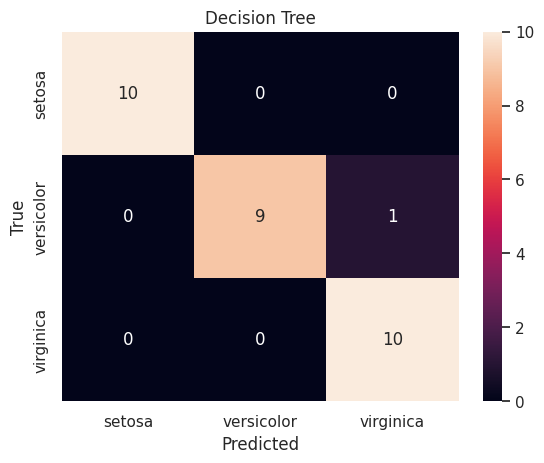

In [23]:
sns.heatmap(confusion_matrix(y_test, pred_tree), annot=True, fmt="d",
            xticklabels=labels, yticklabels=labels)
plt.title("Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

## 7. Decision Boundary Visualization

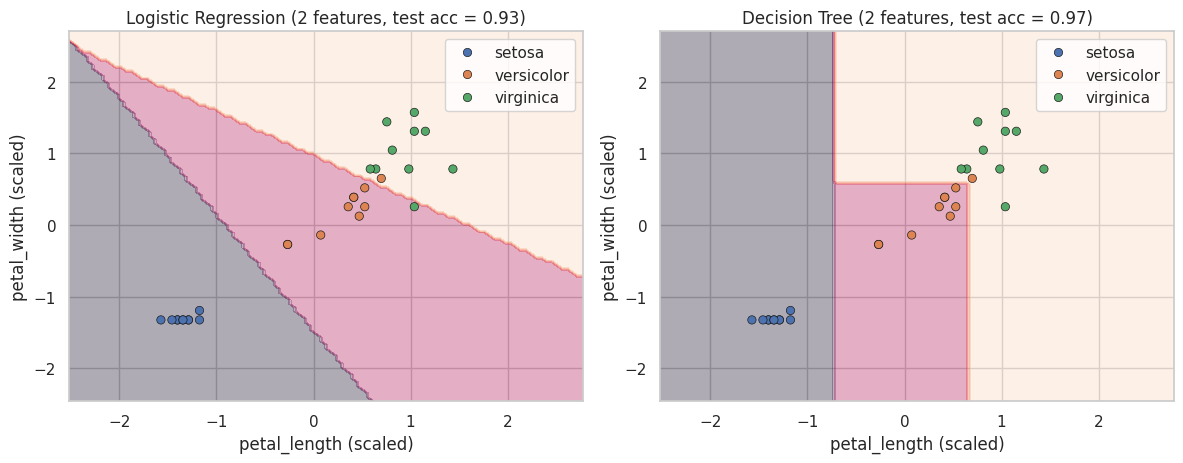

In [26]:
pair = ["petal_length", "petal_width"]
sc2 = StandardScaler()
Xtr2 = sc2.fit_transform(X_train[pair])
Xte2 = sc2.transform(X_test[pair])

classes = sorted(y.unique())
class_to_int = {c: i for i, c in enumerate(classes)}
ytr_int = y_train.map(class_to_int)
yte_int = y_test.map(class_to_int)

models_2d = {
    "Logistic Regression": LogisticRegression(max_iter=200, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (name, m) in zip(axes, models_2d.items()):
    m.fit(Xtr2, ytr_int)
    acc = accuracy_score(yte_int, m.predict(Xte2))
    DecisionBoundaryDisplay.from_estimator(
        m, Xtr2, response_method="predict", alpha=0.35,
        xlabel="petal_length (scaled)", ylabel="petal_width (scaled)", ax=ax)
    sns.scatterplot(x=Xte2[:, 0], y=Xte2[:, 1], hue=y_test.values,
                    hue_order=classes, edgecolor="k", ax=ax)
    ax.set_title(f"{name} (2 features, test acc = {acc:.2f})")

plt.tight_layout()
plt.show()

## 8. Feature Importance

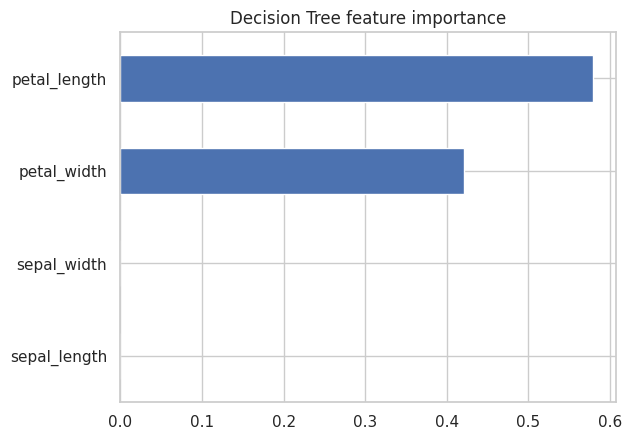

In [27]:
imp = pd.Series(tree.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", title="Decision Tree feature importance")
plt.show()